# 3. Boiling point: frozen MoLFormer embeddings + feed-forward network

**Workshop goal:** use a pretrained molecular language model as a fixed feature extractor, then train a small feed-forward network to predict boiling point. MoLFormer reads each SMILES string and produces an embedding. The large pretrained transformer stays frozen; the regression head learns only from the frozen MoLFormer embedding and boiling-point labels.

[![MoLFormer pretraining and fine-tuning pipeline](https://huggingface.co/ibm-research/MoLFormer-XL-both-10pct/resolve/main/pipeline.jpeg)](https://huggingface.co/ibm-research/MoLFormer-XL-both-10pct)

*Figure 1. MoLFormer pretraining and fine-tuning pipeline, provided with the [IBM MoLFormer-XL pretrained checkpoint](https://huggingface.co/ibm-research/MoLFormer-XL-both-10pct). This workshop freezes the learned encoder and trains a small feed-forward boiling-point head on its embeddings.*

## Workshop workflow

1. Recreate the same reproducible training, validation, and held-out test split used in notebook 02.
2. Convert the split SMILES strings into frozen MoLFormer embeddings.
3. Train a feed-forward regression network on the training embeddings. After each full 20-epoch window, stop only when validation loss exceeds training loss and both its ordinary slope and its slope after removing the five highest recent validation losses are positive.
4. Restore the lowest validation-loss checkpoint that meets the selection rule, then evaluate it once on the held-out test set with a loss plot, parity plot, and good/bad molecular examples.
5. Use the final helper function to predict boiling point for a new SMILES string.

The identical random split makes the Chemprop and MoLFormer demonstrations comparable. It is suitable for this CPU-sized workshop exercise; a scaffold split and repeated cross-validation are sensible next steps for a scientific performance claim.

## Key MoLFormer references

1. [Ross et al. (2022), *Large-scale chemical language representations capture molecular structure and properties*](https://doi.org/10.1038/s42256-022-00580-7) — the MoLFormer architecture, pretraining strategy, and benchmark study.
2. [Ross et al. (2021), *Large-Scale Chemical Language Representations Capture Molecular Structure and Properties*](https://arxiv.org/abs/2106.09553) — open preprint and technical details.
3. [IBM MoLFormer repository](https://github.com/IBM/molformer) — reference implementation, pretrained resources, and embedding-extraction examples.


### Reading and presenting this notebook

The bullet points above each code cell explain what to notice; saved outputs remain visible. In **VS Code**, open the Command Palette (`Ctrl+Shift+P` on Windows/Linux, `Cmd+Shift+P` on macOS) and choose **Notebook: Collapse All Cell Inputs** (search for `Collapse All Cell Inputs`). Use **Expand All Cell Inputs** to edit, or expand an individual cell using its input control. Do not collapse outputs. VS Code can remember your previous view, so use the command if code is still shown. In **JupyterLab**, code inputs are initially hidden via notebook metadata; expand them with the left-hand cell collapser or the View menu. Hiding code does not disable execution or remove it from the file.


**What to notice**

- Use the same reproducible molecular splits as the Chemprop example and keep boiling points in kelvin.
- Configure a frozen MoLFormer encoder and a 64 → 32 → 16 feed-forward head without extra molecular descriptors.
- The head uses a small learning rate, cosine warm restarts, and the robust 20-epoch stopping rule.


In [25]:
import copy
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import HTML, display
from rdkit import Chem
from rdkit.Chem import Draw
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from torch import nn
from torch.utils.data import DataLoader, TensorDataset


def persistent_progress(label, completed, total):
    """Render one static progress bar after a processing stage finishes."""
    percent = 100 * completed / max(total, 1)
    display(HTML(f'<div style="margin:0.35rem 0"><strong>{label}</strong><br>'
                 f'<progress value="{completed}" max="{total}" style="width:22rem"></progress> '
                 f'{completed}/{total} ({percent:.0f}%)</div>'))


# Use the same data-selection and split settings as notebook 02.
SEED = 42
SAMPLE_SIZE = 4600
MODEL_ID = 'ibm-research/MoLFormer-XL-both-10pct'
EMBEDDING_BATCH_SIZE = 32
HEAD_BATCH_SIZE = 64
EPOCHS = 2000
VALIDATION_SLOPE_WINDOW = 20
TRIMMED_SLOPE_EXCLUDED_POINTS = 5
LEARNING_RATE = 3e-6
WEIGHT_DECAY = 1e-5
COSINE_RESTART_EPOCHS = 20
COSINE_RESTART_MULTIPLIER = 2
MIN_LEARNING_RATE = 1e-8
# Three feed-forward layers after the frozen MoLFormer embedding: 16 -> 32 -> 64 units.
HIDDEN_DIMENSIONS = (64, 32, 16)
DROPOUT = 0.01
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

if not 0 <= TRIMMED_SLOPE_EXCLUDED_POINTS < VALIDATION_SLOPE_WINDOW - 1:
    raise ValueError('TRIMMED_SLOPE_EXCLUDED_POINTS must leave at least two points for a slope.')

ACQUIRED_DATA_FILE = Path('outputs/nist_acquisition/NIST_BP_SMILES.parquet')
PACKAGED_DATA_FILE = Path('data/CompoundData.parquet')
DATA_FILE = ACQUIRED_DATA_FILE if ACQUIRED_DATA_FILE.exists() else PACKAGED_DATA_FILE
OUTPUT = Path('outputs/bp_molformer')
FIGURES = OUTPUT / 'figures'
OUTPUT.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)

np.random.seed(SEED)
torch.manual_seed(SEED)
torch.use_deterministic_algorithms(True, warn_only=True)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

raw_data = pd.read_parquet(DATA_FILE).copy()
required_columns = {'SMILES', 'BP'}
missing_columns = required_columns - set(raw_data.columns)
if missing_columns:
    raise ValueError(f'Missing required columns: {sorted(missing_columns)}')

data = raw_data.dropna(subset=['SMILES', 'BP']).drop_duplicates('SMILES')[['SMILES', 'BP']]
data = data.sample(n=min(SAMPLE_SIZE, len(data)), random_state=SEED).reset_index(drop=True)
invalid_smiles = data.SMILES.map(Chem.MolFromSmiles).isna().sum()
if invalid_smiles:
    raise ValueError(f'Sampled data contain {invalid_smiles} invalid SMILES strings.')

# This is intentionally identical to the split recipe in notebook 02: 80% / 10% / 10%.
indices = np.arange(len(data))
train_indices, held_out_indices = train_test_split(indices, test_size=0.20, random_state=SEED)
val_indices, test_indices = train_test_split(held_out_indices, test_size=0.50, random_state=SEED)
data['split'] = 'train'
data.loc[val_indices, 'split'] = 'val'
data.loc[test_indices, 'split'] = 'test'
if set(data['split']) != {'train', 'val', 'test'} or data.SMILES.duplicated().any():
    raise ValueError('Split validation failed: each unique molecule must have exactly one split.')

train_data = data.loc[data.split == 'train'].reset_index(drop=True)
val_data = data.loc[data.split == 'val'].reset_index(drop=True)
test_data = data.loc[data.split == 'test'].reset_index(drop=True)
data.to_csv(OUTPUT / 'bp_data.csv', index=False)
print(f'Using data source: {DATA_FILE} on {DEVICE}.')
display(data.groupby('split')['BP'].agg(n='size', minimum_K='min', mean_K='mean', maximum_K='max').reindex(['train', 'val', 'test']).round(2))


Using data source: outputs\nist_acquisition\NIST_BP_SMILES.parquet on cpu.


,n,minimum_K,mean_K,maximum_K
split,,,,
train,3680,29.90,449.72,721.2
val,460,146.50,447.74,644.2
test,460,273.15,450.04,686.2


**What to notice**

- Load the public MoLFormer model and freeze its weights; the first run requires a model download.
- Convert SMILES into fixed embeddings, then fit embedding and target standardization on training data only.


In [26]:
try:
    from transformers import AutoModel, AutoTokenizer
except ImportError as error:
    raise ImportError('Install the workshop environment; it includes transformers.') from error

tokenizer = AutoTokenizer.from_pretrained(MODEL_ID, trust_remote_code=True)
encoder = AutoModel.from_pretrained(MODEL_ID, deterministic_eval=True, trust_remote_code=True).to(DEVICE).eval()
for parameter in encoder.parameters():
    parameter.requires_grad = False

@torch.inference_mode()
def embed_smiles(smiles_list, description='Creating frozen embeddings'):
    """Return one fixed MoLFormer embedding per SMILES string."""
    vectors = []
    for start in range(0, len(smiles_list), EMBEDDING_BATCH_SIZE):
        batch = smiles_list[start:start + EMBEDDING_BATCH_SIZE]
        tokens = tokenizer(batch, padding=True, truncation=True, max_length=202, return_tensors='pt').to(DEVICE)
        outputs = encoder(**tokens)
        pooled = getattr(outputs, 'pooler_output', None)
        if pooled is None:
            hidden = outputs.last_hidden_state
            mask = tokens['attention_mask'].unsqueeze(-1).to(hidden.dtype)
            pooled = (hidden * mask).sum(1) / mask.sum(1).clamp_min(1)
        vectors.append(pooled.float().cpu().numpy())
    return np.vstack(vectors)

train_embedding = embed_smiles(train_data.SMILES.tolist(), 'Embedding training molecules')
val_embedding = embed_smiles(val_data.SMILES.tolist(), 'Embedding validation molecules')
test_embedding = embed_smiles(test_data.SMILES.tolist(), 'Embedding test molecules')
persistent_progress('MoLFormer embedding extraction complete', len(data), len(data))
np.savez_compressed(OUTPUT / 'frozen_embeddings.npz', train=train_embedding, validation=val_embedding, test=test_embedding)

# Fit all preprocessing quantities using training data only.
embedding_mean = train_embedding.mean(axis=0, keepdims=True)
embedding_std = train_embedding.std(axis=0, keepdims=True).clip(1e-6)
target_mean = float(train_data.BP.mean())
target_std = float(train_data.BP.std())

def prepare_embeddings(values):
    return ((values - embedding_mean) / embedding_std).astype(np.float32)

def prepare_targets(values):
    return ((np.asarray(values, dtype=np.float32) - target_mean) / target_std).reshape(-1, 1)

train_dataset = TensorDataset(torch.from_numpy(prepare_embeddings(train_embedding)), torch.from_numpy(prepare_targets(train_data.BP)))
val_dataset = TensorDataset(torch.from_numpy(prepare_embeddings(val_embedding)), torch.from_numpy(prepare_targets(val_data.BP)))
test_dataset = TensorDataset(torch.from_numpy(prepare_embeddings(test_embedding)), torch.from_numpy(prepare_targets(test_data.BP)))
loader_generator = torch.Generator().manual_seed(SEED)
train_loader = DataLoader(train_dataset, batch_size=HEAD_BATCH_SIZE, shuffle=True, generator=loader_generator)
val_loader = DataLoader(val_dataset, batch_size=HEAD_BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=HEAD_BATCH_SIZE, shuffle=False)
print('Frozen MoLFormer embedding shapes:', train_embedding.shape, val_embedding.shape, test_embedding.shape)

Loading weights: 100%|██████████| 207/207 [00:00<00:00, 1203.91it/s]
[transformers] MolformerModel LOAD REPORT from: ibm-research/MoLFormer-XL-both-10pct
Key                                | Status     |  | 
-----------------------------------+------------+--+-
lm_head.decoder.weight             | UNEXPECTED |  | 
lm_head.transform.dense.weight     | UNEXPECTED |  | 
lm_head.transform.dense.bias       | UNEXPECTED |  | 
lm_head.transform.LayerNorm.bias   | UNEXPECTED |  | 
lm_head.transform.LayerNorm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Frozen MoLFormer embedding shapes: (3680, 768) (460, 768) (460, 768)


**What to notice**

- Train only the regression head with AdamW/MSE, cosine warm restarts, and gradient clipping.
- Require positive raw and top-five-trimmed validation slopes plus validation loss above training loss to stop.
- Restore the lowest eligible validation-loss epoch, with an overall-minimum fallback; the epoch cap is not proof of convergence.


In [27]:
class FrozenEmbeddingRegressor(nn.Module):
    """A feed-forward regression head; the MoLFormer encoder remains frozen."""
    def __init__(self, input_dim, hidden_dimensions=HIDDEN_DIMENSIONS, dropout=DROPOUT):
        super().__init__()
        layers = [nn.LayerNorm(input_dim)]
        previous_dim = input_dim
        for hidden_dim in hidden_dimensions:
            layers.extend([nn.Linear(previous_dim, hidden_dim), nn.ReLU(), nn.Dropout(dropout)])
            previous_dim = hidden_dim
        layers.append(nn.Linear(previous_dim, 1))
        self.network = nn.Sequential(*layers)

    def forward(self, embeddings):
        return self.network(embeddings)


def robust_validation_slopes(losses):
    """Return the ordinary and five-highest-values-removed slopes from one 20-epoch window."""
    losses = np.asarray(losses, dtype=float)
    x_values = np.arange(len(losses), dtype=float)
    raw_slope = float(np.polyfit(x_values, losses, deg=1)[0])
    keep = np.ones(len(losses), dtype=bool)
    highest_indices = np.argsort(losses)[-TRIMMED_SLOPE_EXCLUDED_POINTS:]
    keep[highest_indices] = False
    trimmed_slope = float(np.polyfit(x_values[keep], losses[keep], deg=1)[0])
    return raw_slope, trimmed_slope


head = FrozenEmbeddingRegressor(train_embedding.shape[1]).to(DEVICE)
criterion = nn.MSELoss()
optimizer = torch.optim.AdamW(head.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.CosineAnnealingWarmRestarts(
    optimizer, T_0=COSINE_RESTART_EPOCHS, T_mult=COSINE_RESTART_MULTIPLIER, eta_min=MIN_LEARNING_RATE
)


@torch.inference_mode()
def mean_loss(loader):
    head.eval()
    total_loss, total_items = 0.0, 0
    for features, targets in loader:
        features, targets = features.to(DEVICE), targets.to(DEVICE)
        loss = criterion(head(features), targets)
        total_loss += loss.item() * len(targets)
        total_items += len(targets)
    return total_loss / total_items


history = []
best_validation_loss = float('inf')
best_epoch = 0
best_state = None
fallback_validation_loss = float('inf')
fallback_epoch = 0
fallback_state = None
stopped_by_slope_rule = False
final_raw_slope = float('nan')
final_trimmed_slope = float('nan')

for epoch in range(1, EPOCHS + 1):
    scheduler.step(epoch - 1)
    current_learning_rate = optimizer.param_groups[0]['lr']
    head.train()
    total_train_loss, total_train_items = 0.0, 0
    for features, targets in train_loader:
        features, targets = features.to(DEVICE), targets.to(DEVICE)
        optimizer.zero_grad()
        loss = criterion(head(features), targets)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(head.parameters(), max_norm=1.0)
        optimizer.step()
        total_train_loss += loss.item() * len(targets)
        total_train_items += len(targets)

    train_loss = total_train_loss / total_train_items
    validation_loss = mean_loss(val_loader)
    record = {'epoch': epoch, 'train_loss': train_loss, 'validation_loss': validation_loss,
              'learning_rate': current_learning_rate, 'raw_validation_slope': np.nan,
              'trimmed_validation_slope': np.nan}
    history.append(record)

    if validation_loss < fallback_validation_loss:
        fallback_validation_loss = validation_loss
        fallback_epoch = epoch
        fallback_state = copy.deepcopy(head.state_dict())

    # Candidates must have validation loss above training loss, as requested.
    if validation_loss > train_loss and validation_loss < best_validation_loss:
        best_validation_loss = validation_loss
        best_epoch = epoch
        best_state = copy.deepcopy(head.state_dict())

    # A rising slope must survive removal of the five largest losses, preventing brief spikes
    # from ending training.  This is the same stopping rule used in notebook 02.
    if len(history) >= VALIDATION_SLOPE_WINDOW:
        recent_validation_loss = [row['validation_loss'] for row in history[-VALIDATION_SLOPE_WINDOW:]]
        raw_slope, trimmed_slope = robust_validation_slopes(recent_validation_loss)
        record['raw_validation_slope'] = raw_slope
        record['trimmed_validation_slope'] = trimmed_slope
        final_raw_slope, final_trimmed_slope = raw_slope, trimmed_slope
        robustly_rising = raw_slope > 0 and trimmed_slope > 0
        if robustly_rising and validation_loss > train_loss:
            stopped_by_slope_rule = True
            print(f'Stopping after epoch {epoch}: raw {VALIDATION_SLOPE_WINDOW}-epoch slope = {raw_slope:.5f}; '
                  f'slope after removing the {TRIMMED_SLOPE_EXCLUDED_POINTS} highest losses = '
                  f'{trimmed_slope:.5f}; validation loss exceeds training loss.')
            break

if best_state is None:
    best_validation_loss = fallback_validation_loss
    best_epoch = fallback_epoch
    best_state = fallback_state
    print('Validation loss never exceeded training loss; restored the overall lowest-validation-loss checkpoint.')
head.load_state_dict(best_state)
history = pd.DataFrame(history)
persistent_progress('Feed-forward head training complete', len(history), EPOCHS)
history.to_csv(OUTPUT / 'training_history.csv', index=False)
torch.save({'head_state_dict': head.state_dict(), 'input_dimension': train_embedding.shape[1],
            'hidden_dimensions': HIDDEN_DIMENSIONS, 'embedding_mean': embedding_mean,
            'embedding_std': embedding_std, 'target_mean': target_mean, 'target_std': target_std,
            'model_id': MODEL_ID, 'best_epoch': best_epoch, 'best_validation_loss': best_validation_loss,
            'validation_slope_window': VALIDATION_SLOPE_WINDOW,
            'trimmed_slope_excluded_points': TRIMMED_SLOPE_EXCLUDED_POINTS,
            'last_raw_validation_slope': final_raw_slope,
            'last_trimmed_validation_slope': final_trimmed_slope,
            'stopped_by_slope_rule': stopped_by_slope_rule},
           OUTPUT / 'best_frozen_molformer_head.pt')
print(f'Restored the epoch-{best_epoch} head with the selected validation loss: {best_validation_loss:.4f}.')


Stopping after epoch 1593: raw 20-epoch slope = 0.00000; slope after removing the 5 highest losses = 0.00000; validation loss exceeds training loss.


Restored the epoch-1579 head with the selected validation loss: 0.1858.


**What to notice**

- Plot training/validation standardized MSE and learning rate after training completes.
- Mark the selected checkpoint and any robust-slope stopping epoch, rather than labeling every upward fluctuation.


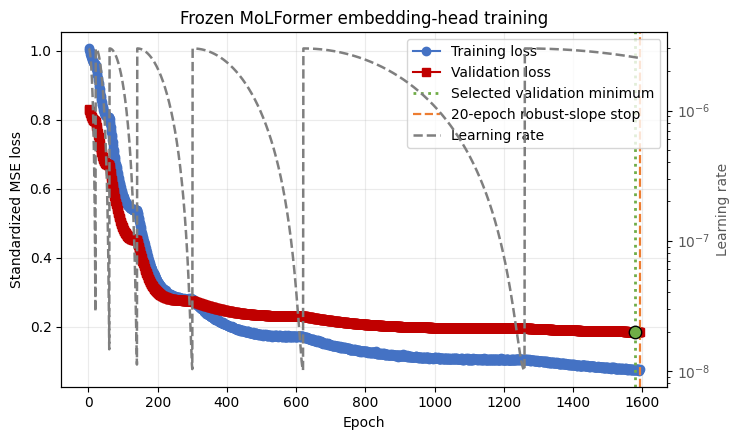

In [31]:
fig, ax = plt.subplots(figsize=(7.5, 4.5))
ax.plot(history.epoch, history.train_loss, marker='o', color='#4472C4', label='Training loss')
ax.plot(history.epoch, history.validation_loss, marker='s', color='#C00000', label='Validation loss')
eligible_history = history.loc[history.validation_loss > history.train_loss]
selection_history = eligible_history if not eligible_history.empty else history
best_row = selection_history.loc[selection_history.validation_loss.idxmin()]
ax.axvline(best_row.epoch, color='#70AD47', linestyle=':', linewidth=2, label='Selected validation minimum')
ax.scatter(best_row.epoch, best_row.validation_loss, s=80, color='#70AD47', edgecolor='black', zorder=5)
lr_axis = ax.twinx()
lr_axis.plot(history.epoch, history.learning_rate, color='#7F7F7F', linestyle='--', linewidth=1.8, label='Learning rate')
lr_axis.set_ylabel('Learning rate', color='#595959')
lr_axis.set_yscale('log')
lr_axis.tick_params(axis='y', labelcolor='#595959')
if stopped_by_slope_rule:
    ax.axvline(history.epoch.iloc[-1], color='#ED7D31', linestyle='--', linewidth=1.6,
               label=f'{VALIDATION_SLOPE_WINDOW}-epoch robust-slope stop')
ax.set(xlabel='Epoch', ylabel='Standardized MSE loss', title='Frozen MoLFormer embedding-head training')
ax.grid(alpha=0.25)
loss_handles, loss_labels = ax.get_legend_handles_labels()
lr_handles, lr_labels = lr_axis.get_legend_handles_labels()
ax.legend(loss_handles + lr_handles, loss_labels + lr_labels, loc='upper right')
fig.tight_layout()
fig.savefig(FIGURES / 'training_validation_loss.png', dpi=180, bbox_inches='tight')
plt.show()


**What to notice**

- Undo target standardization before calculating boiling-point errors in kelvin.
- Compare all three split parity plots on the same axes and inspect good/bad held-out molecules.
- Save the metrics and test predictions for the restored head.


,split,selected_epoch,best_validation_scaled_MSE,MSE_K2,MAE_K,RMSE_K,R2
0,train,1579,0.186,372.773,11.780,19.307,0.931
1,validation,1579,0.186,1009.600,19.127,31.774,0.774
2,test,1579,0.186,605.537,17.610,24.608,0.865


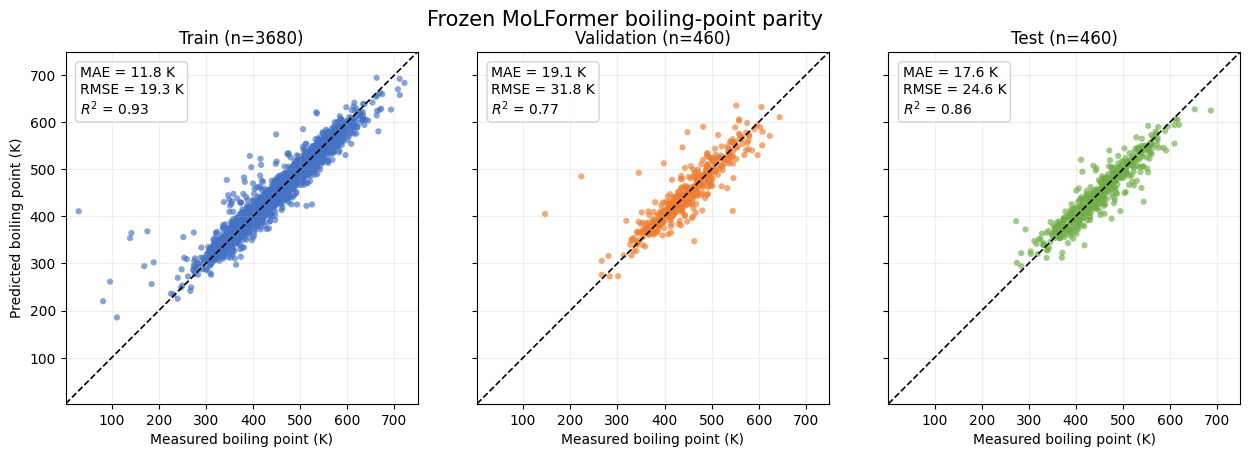

,SMILES,BP,predicted_BP_K,absolute_error_K
122,CC(C)OC(C)OC(C)C,395.0,395.000000,0.00
379,CC(=O)OC1CCC1,404.0,403.929993,0.07
395,CC1CCCC(C)C1O,447.7,447.619995,0.08
200,C=CCCCCCC=C,415.7,415.619995,0.08


,SMILES,BP,predicted_BP_K,absolute_error_K
389,CC1(N)CCCC1,273.15,389.619995,116.47
108,CC1=CCC(C(C)(C)[O])CC1[O],543.70,430.880005,112.82
449,CCCCCCCCCCCCC(C)C(=O)OC,411.00,519.890015,108.89
239,CC(N)=O,494.40,410.950012,83.45


Lowest-error held-out examples


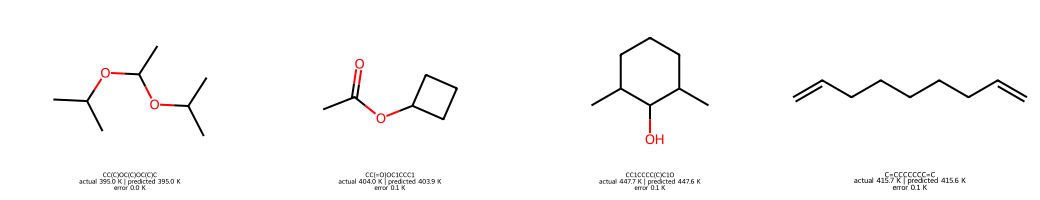

Highest-error held-out examples


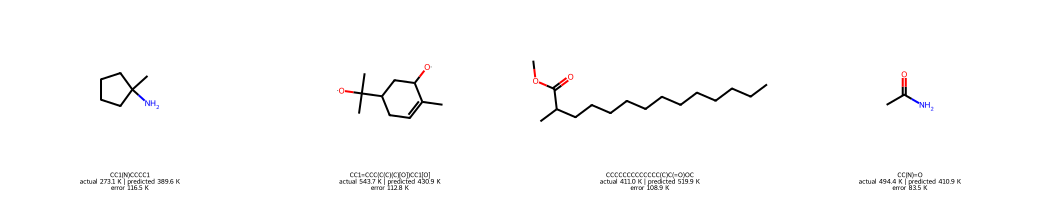

In [32]:
@torch.inference_mode()
def predict_from_embeddings(embeddings):
    head.eval()
    values = torch.from_numpy(prepare_embeddings(embeddings)).to(DEVICE)
    scaled_prediction = head(values).cpu().numpy().ravel()
    return scaled_prediction * target_std + target_mean

train_prediction = predict_from_embeddings(train_embedding)
val_prediction = predict_from_embeddings(val_embedding)
test_prediction = predict_from_embeddings(test_embedding)
split_results = {}
for split_name, frame, prediction in [('train', train_data, train_prediction),
                                      ('validation', val_data, val_prediction),
                                      ('test', test_data, test_prediction)]:
    result = frame[['SMILES', 'BP']].copy()
    result['predicted_BP_K'] = prediction
    result['absolute_error_K'] = (result.BP - result.predicted_BP_K).abs()
    split_results[split_name] = result

test_results = split_results['test']
test_results.to_csv(OUTPUT / 'test_predictions.csv', index=False)

def split_metrics(name, frame, prediction):
    actual = frame.BP.to_numpy()
    return {'split': name, 'MSE_K2': mean_squared_error(actual, prediction),
            'MAE_K': mean_absolute_error(actual, prediction),
            'RMSE_K': mean_squared_error(actual, prediction) ** 0.5,
            'R2': r2_score(actual, prediction)}

metrics = pd.DataFrame([split_metrics('train', train_data, train_prediction),
                        split_metrics('validation', val_data, val_prediction),
                        split_metrics('test', test_data, test_prediction)])
metrics.insert(1, 'selected_epoch', best_epoch)
metrics.insert(2, 'best_validation_scaled_MSE', best_validation_loss)
metrics.to_csv(OUTPUT / 'split_metrics.csv', index=False)
display(metrics.round(3))

# Match the three-split parity format used in the Chemprop notebook.
metric_by_split = metrics.set_index('split')
colors = {'train': '#4472C4', 'validation': '#ED7D31', 'test': '#70AD47'}
all_values = np.concatenate([np.concatenate([result.BP.to_numpy(), result.predicted_BP_K.to_numpy()])
                             for result in split_results.values()])
padding = 0.04 * (all_values.max() - all_values.min())
limits = (all_values.min() - padding, all_values.max() + padding)
fig, axes = plt.subplots(1, 3, figsize=(13, 4.4), sharex=True, sharey=True)
for ax, split_name in zip(axes, ['train', 'validation', 'test']):
    result = split_results[split_name]
    ax.scatter(result.BP, result.predicted_BP_K, s=20, alpha=0.65, color=colors[split_name], edgecolor='none')
    ax.plot(limits, limits, 'k--', linewidth=1.2)
    ax.set(title=f'{split_name.title()} (n={len(result)})', xlabel='Measured boiling point (K)',
           xlim=limits, ylim=limits)
    ax.set_aspect('equal', adjustable='box')
    ax.grid(alpha=0.20)
    row = metric_by_split.loc[split_name]
    ax.text(0.04, 0.96, f"MAE = {row['MAE_K']:.1f} K\nRMSE = {row['RMSE_K']:.1f} K\n$R^2$ = {row['R2']:.2f}",
            transform=ax.transAxes, va='top', bbox={'boxstyle': 'round', 'facecolor': 'white',
                                                     'alpha': 0.85, 'edgecolor': '0.8'})
axes[0].set_ylabel('Predicted boiling point (K)')
fig.suptitle('Frozen MoLFormer boiling-point parity', fontsize=15)
fig.tight_layout()
fig.savefig(FIGURES / 'parity_train_val_test.png', dpi=250, bbox_inches='tight')
plt.show()

good_examples = test_results.nsmallest(4, 'absolute_error_K')
bad_examples = test_results.nlargest(4, 'absolute_error_K')
display(good_examples.round(2))
display(bad_examples.round(2))

def display_molecule_examples(examples, title):
    molecules = [Chem.MolFromSmiles(smiles) for smiles in examples.SMILES]
    legends = [f'{smiles}\nactual {actual:.1f} K | predicted {predicted:.1f} K\nerror {error:.1f} K'
               for smiles, actual, predicted, error in zip(examples.SMILES, examples.BP,
                                                           examples.predicted_BP_K, examples.absolute_error_K)]
    print(title)
    display(Draw.MolsToGridImage(molecules, molsPerRow=4, subImgSize=(260, 200), legends=legends))

display_molecule_examples(good_examples, 'Lowest-error held-out examples')
display_molecule_examples(bad_examples, 'Highest-error held-out examples')

**What to notice**

- Predict a new SMILES using the frozen encoder, training-fitted scaling, and restored head.
- Edit the example SMILES and read the resulting boiling point in kelvin.


In [34]:
def predict_boiling_point(smiles):
    """Predict a boiling point in K from one valid SMILES string using the selected head."""
    if not isinstance(smiles, str) or Chem.MolFromSmiles(smiles) is None:
        raise ValueError('Provide one valid SMILES string, for example CCO for ethanol.')
    embedding = embed_smiles([smiles], description='Embedding input SMILES')
    return float(predict_from_embeddings(embedding)[0])

SMILES_TO_PREDICT = 'CCO'  # Replace with a valid SMILES string.
predicted_bp = predict_boiling_point(SMILES_TO_PREDICT)
print(f'Predicted boiling point for {SMILES_TO_PREDICT}: {predicted_bp:.1f} K')

Predicted boiling point for CCO: 312.3 K


**What to notice**

- Optional blank practice cell: expand it for your own follow-up prediction or analysis.
- This cell does not contain another model or training step.
